In [1]:
import numpy as np
import matplotlib.pyplot as plt

import helpers
from compression import zstd

In [2]:
x_train, x_test, y_train, train_ids, test_ids = helpers.load_data("../data")

In [3]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)

(328135, 321)
(109379, 321)
(328135,)


## Exploratory Data Analysis

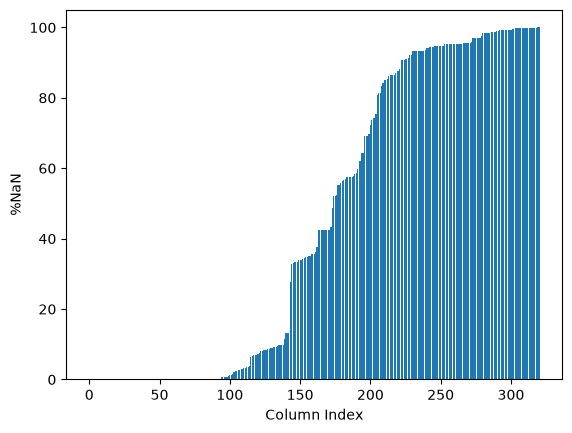

In [4]:

nan_frac = np.isnan(x_train).mean(axis=0)
nan_sort = np.sort(nan_frac, axis=0)

plt.bar(np.arange(x_train.shape[1]), nan_sort*100)
plt.xlabel("Column Index")
plt.ylabel("%NaN")
plt.show()

A lot of columns are majority NaN. We should pich a threshold to drop these columns.<br/>

In [5]:
with zstd.open("../data/x_train.csv.zst", "rt") as f:
    header = f.readline()
col_names = np.array(header.strip().split(",")[1:])
idx = {name: j for j, name in enumerate(col_names)}

In [6]:
n_unique = np.array([len(np.unique(c[~np.isnan(c)])) for c in x_train.T])

def summary(j):
    c = x_train[:, j]; c = c[~np.isnan(c)]
    vals, counts = np.unique(c, return_counts=True)
    top = vals[np.argsort(counts)[::-1][:5]]
    return f"{col_names[j]:<10} nan={nan_frac[j]:.0%} uniq={n_unique[j]:<5} min={c.min():g} max={c.max():g} top={top}"

for j in np.argsort(nan_frac):
    print(summary(j))


_STATE     nan=0% uniq=53    min=1 max=72 top=[20. 31. 27. 53. 48.]
PERSDOC2   nan=0% uniq=5     min=1 max=9 top=[1. 3. 2. 7. 9.]
HLTHPLN1   nan=0% uniq=4     min=1 max=9 top=[1. 2. 7. 9.]
MENTHLTH   nan=0% uniq=33    min=1 max=99 top=[88. 30.  2.  5.  1.]
BLOODCHO   nan=0% uniq=4     min=1 max=9 top=[1. 2. 7. 9.]
CHCOCNCR   nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
ASTHMA3    nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
PAMISS1_   nan=0% uniq=3     min=0 max=9 top=[0. 9. 1.]
CVDSTRK3   nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
EMPLOY1    nan=0% uniq=9     min=1 max=9 top=[1. 7. 2. 8. 5.]
MARITAL    nan=0% uniq=7     min=1 max=9 top=[1. 5. 2. 3. 6.]
EDUCA      nan=0% uniq=7     min=1 max=9 top=[6. 4. 5. 3. 2.]
SEX        nan=0% uniq=2     min=1 max=2 top=[2. 1.]
CHCKIDNY   nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
ADDEPEV2   nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
CHCCOPD1   nan=0% uniq=4     min=1 max=9 top=[2. 1. 7. 9.]
RENTHOM1   nan=0% uniq=5     min=1 

Some columns have weird values such as [88. 14.  2. 77.  3.] for ADDOWN, ADSLEEP etc. Looking at the documentation of the [dataset](https://www.cdc.gov/brfss/annual_data/annual_2022.html), we can see that certain columns use codes such as:
- 7 / 77 / 777 / 7777: don't know / not sure
- 9 / 99 / 999 / 9999: refused

## Relationship with positive cases 

We find the rate of positive and negative cases:

In [7]:
pos = y_train == 1
print(f"base rate: {pos.mean():.3f}")

base rate: 0.088


For each categorical column (2 to 10 distinct values), we split the rows by their answer and compute the positive rate in each group. For example, for CVDSTRK3 (ever had a stroke?), people who answered YES are positive far more often than 8.8%, while those who answered NO are below it. A column like the interview month gives ~8.8% in every group, so it carries no signal.

We measure this with [Cramér's V](https://en.wikipedia.org/wiki/Cram%C3%A9r%27s_V), the effect size of [Pearson's chi-squared test of independence](https://en.wikipedia.org/wiki/Pearson%27s_chi-squared_test) between the column and the label. With a binary label, the chi-squared statistic simplifies to
$$\chi^2 = \sum_v \frac{n_v\,(r_v - p)^2}{p(1-p)}, \qquad V = \sqrt{\chi^2 / N}$$

In [14]:
pos = y_train == 1
print(f"base rate: {pos.mean():.3f}")

rows = []
for j in np.where((n_unique > 1) & (n_unique <= 10) & (nan_frac < 0.8))[0]:
    c = x_train[:, j]
    ok = ~np.isnan(c)
    p = pos[ok].mean()
    if not 0 < p < 1:
        continue
    vals, inv, counts = np.unique(c[ok], return_inverse=True, return_counts=True)
    rates = np.bincount(inv, weights=pos[ok]) / counts
    chi2 = np.sum(counts * (rates - p) ** 2) / (p * (1 - p))
    v = np.sqrt(chi2 / ok.sum())  # Cramer's V
    rows.append((v, j, vals, rates, counts))

for v, j, vals, rates, counts in sorted(rows, key=lambda r: -r[0])[:20]:
    desc = " ".join(f"{val}:{r}({n // 1000}k)" for val, r, n in zip(vals, rates, counts))
    print(f"{col_names[j]} V={v} nan={nan_frac[j]}  {desc}")


base rate: 0.088
GENHLTH V=0.2663789716847007 nan=6.095052341261981e-06  1.0:0.020531464601225916(56k) 2.0:0.04235398606703735(108k) 3.0:0.09130349430702787(101k) 4.0:0.19292255876721492(43k) 5.0:0.3190324858757062(16k) 7.0:0.1708185053380783(0k) 9.0:0.1419753086419753(0k)
_RFHLTH V=0.23520652103007908 nan=0.0  1.0:0.0563831461263516(266k) 2.0:0.22843506073813824(60k) 9.0:0.15990990990990991(0k)
EMPLOY1 V=0.2313923084722877 nan=0.0  1.0:0.03170291207068973(133k) 2.0:0.05481214616572311(27k) 3.0:0.08691322901849217(7k) 4.0:0.04684226279557019(6k) 5.0:0.06381601871671064(20k) 6.0:0.007890222984562607(8k) 7.0:0.1613284554005442(98k) 8.0:0.21048816883393734(23k) 9.0:0.06870772516909933(2k)
_AGE_G V=0.22213771831269058 nan=0.0  1.0:0.005124814018846091(18k) 2.0:0.009984614901566768(31k) 3.0:0.01913066455278108(37k) 4.0:0.04752478945304476(53k) 5.0:0.08593154859070629(73k) 6.0:0.16760427798041172(113k)
BPHIGH4 V=0.21757690947871816 nan=3.0475261706309903e-06  1.0:0.16335232661360688(131k) 2.

For continuous columns: standardized mean difference between classes, d = (mean(y=1) - mean(y=-1)) / std.

In [9]:
rows = []
for j in np.where((n_unique > 10) & (nan_frac < 0.8))[0]:
    c = x_train[:, j]
    ok = ~np.isnan(c)
    d = (c[ok & pos].mean() - c[ok & ~pos].mean()) / c[ok].std()
    rows.append((abs(d), j, d))
    

for _, j, d in sorted(rows, reverse=True)[:15]:
    print(f"{col_names[j]} d={d}")

_AGE80 d=0.7914019756550319
_AGEG5YR d=0.771874748662579
CHILDREN d=0.4021157118827377
PHYSHLTH d=-0.3431983772440607
ALCDAY5 d=0.3070414851477544
PA1VIGM_ d=0.23608760220167746
STRENGTH d=0.23155729480200293
NUMWOMEN d=-0.21576627602931633
DRNK3GE5 d=0.21424865375574914
PAVIG11_ d=0.2022264029613272
NUMADULT d=-0.19796060922827632
_BMI5 d=0.18900699788790104
WTKG3 d=0.18605832277290343
HIVTSTD3 d=0.18451562373100563
_PSU d=-0.1778965561817243


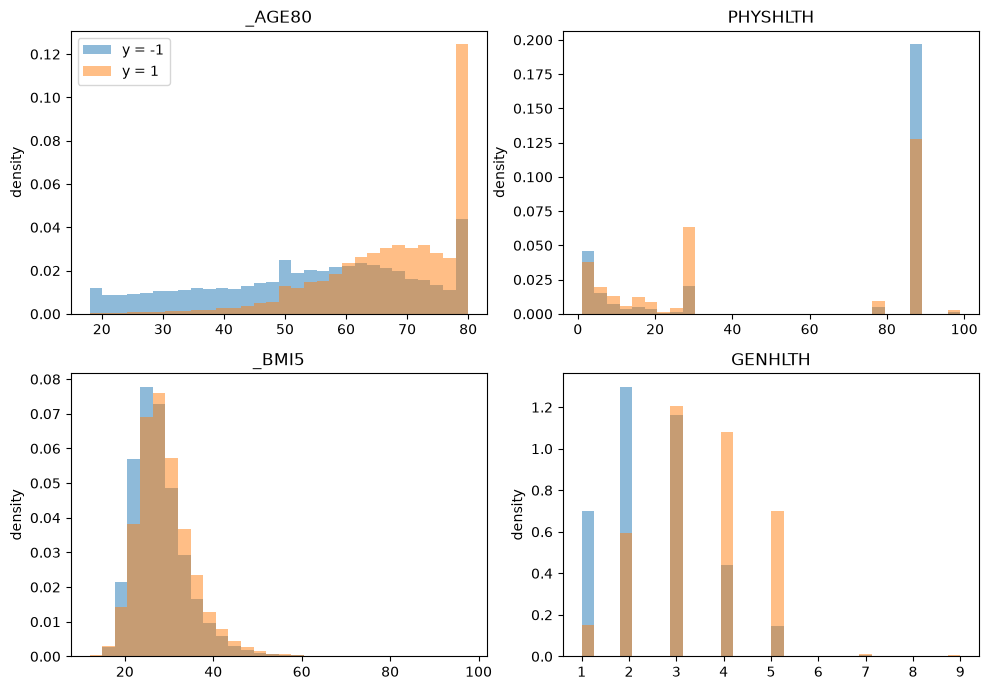

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, name in zip(axes.flat, ["_AGE80", "PHYSHLTH", "_BMI5", "GENHLTH"]):
    c = x_train[:, idx[name]]
    ok = ~np.isnan(c)
    bins = np.histogram_bin_edges(c[ok], bins=30)
    ax.hist(c[ok & ~pos], bins=bins, density=True, alpha=0.5, label="y = -1")
    ax.hist(c[ok & pos], bins=bins, density=True, alpha=0.5, label="y = 1")
    ax.set_title(name)
    ax.set_ylabel("density")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## Conditioning on NaN

Some questions questions are only asked if a previous answer triggers them (e.g. the diabetes module is only asked to diabetics). Therefore we check whether:
$$P(Y = 1 \mid \text{NaN})$$
 
is informative for each column

In [11]:
rows = []
for j in range(x_train.shape[1]):
    m = np.isnan(x_train[:, j])
    if 0 < m.sum():
        rows.append((abs(pos[m].mean() - pos[~m].mean()), j, pos[m].mean(), pos[~m].mean(), (~m).sum()))

for _, j, p_nan, p_present, n in sorted(rows, reverse=True)[:15]:
    print(f"{col_names[j]} present={n} P(y=1|nan)={p_nan}  P(y=1|present)={p_present}")

HAREHAB1 present=773 P(y=1|nan)=0.08614927816912164  P(y=1|present)=1.0
STREHAB1 present=517 P(y=1|nan)=0.08787673448955796  P(y=1|present)=0.3578336557059961
CDHELP present=3084 P(y=1|nan)=0.08641720837653168  P(y=1|present)=0.28696498054474706
DIABAGE2 present=42220 P(y=1|nan)=0.06865676862004443  P(y=1|present)=0.22134059687351965
CDDISCUS present=9620 P(y=1|nan)=0.08411534778581857  P(y=1|present)=0.22692307692307692
CDSOCIAL present=9630 P(y=1|nan)=0.08411170939231723  P(y=1|present)=0.2268951194184839
CDASSIST present=9646 P(y=1|nan)=0.08410965527851826  P(y=1|present)=0.22672610408459465
CDHOUSE present=9658 P(y=1|nan)=0.08410968452980906  P(y=1|present)=0.2265479395319942
BLDSUGAR present=21709 P(y=1|nan)=0.07901418286959984  P(y=1|present)=0.21940209129853977
DIABEDU present=21705 P(y=1|nan)=0.07901641484188884  P(y=1|present)=0.2193964524303156
DIABEYE present=21705 P(y=1|nan)=0.07901641484188884  P(y=1|present)=0.2193964524303156
INSULIN present=21710 P(y=1|nan)=0.0790144407

HAREHAB1 is the code for had heart attack before, this could be a leak?

## Feature Engineering:

1. Number of diseases

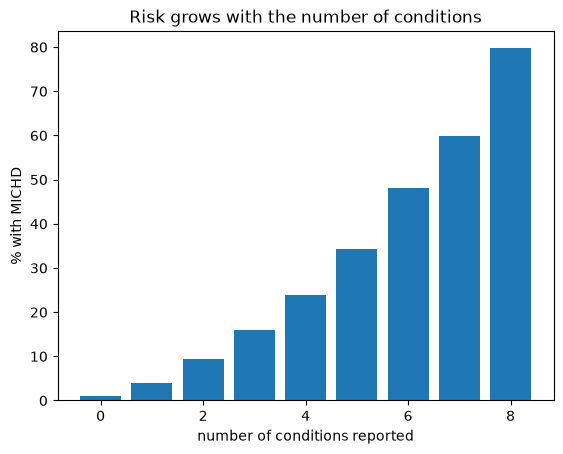

In [12]:
# Health conditions we count, all coded 1 = "yes"
CONDITIONS = {
    "CVDSTRK3": "stroke",
    "BPHIGH4": "high blood pressure",
    "TOLDHI2": "high cholesterol",
    "DIABETE3": "diabetes",
    "CHCKIDNY": "kidney disease",
    "CHCCOPD1": "COPD",
    "HAVARTH3": "arthritis",
    "DIFFWALK": "difficulty walking",
}

# For each respondent, find the num of diseases
n_conditions = np.zeros(len(x_train))
for column in CONDITIONS:
    n_conditions += x_train[:, idx[column]] == 1

# Share of people with MICHD for each number of conditions
levels = np.unique(n_conditions)
pct_positive = []
for k in levels:
    group = n_conditions == k
    pct_positive.append(pos[group].mean() * 100)


plt.bar(levels, pct_positive)
plt.xlabel("number of conditions reported")
plt.ylabel("% with MICHD")
plt.title("Risk grows with the number of conditions")
plt.show()


2. Interaction: sex × agem

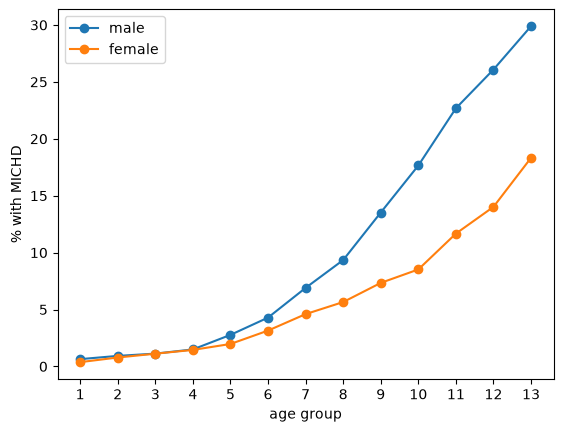

In [13]:
sex = x_train[:, idx["SEX"]]
age = x_train[:, idx["_AGEG5YR"]] 
ages = np.arange(1, 14)
for s, label in [(1, "male"), (2, "female")]:
    plt.plot(ages, [pos[(sex == s) & (age == a)].mean() * 100 for a in ages], marker="o", label=label)
plt.xticks(ages)
plt.xlabel("age group")
plt.ylabel("% with MICHD")
plt.legend()
plt.show()